# Primera ablación: ¿qué aporta centrar la historia residual?

Comparamos POD, PCA centrada y PCA + media. Solo cambia la construcción de la base dentro del selector. Sobol sirve como control. Esta es la línea propia de PCA; no usa la transformación de salida ni la pérdida de la reproducción QR-DEIM del notebook 14.

## Hipótesis y dimensión comparable

Fijamos **4 direcciones totales**, antes de ejecutar: POD toma los modos de R; PCA toma los modos de R centrada por la media temporal de cada punto; PCA + media reserva una dirección para la media y añade direcciones PCA independientes hasta completar el mismo total. La media cuenta dentro del presupuesto, nunca se añade como una quinta dirección.

Todas las bases se ortonormalizan antes del mismo QR con pivoteo y la misma ampliación log-det (ridge 1e-10). PCA + media conserva la media primero y ortogonaliza sucesivamente los modos PCA; si un modo es dependiente, continúa con el siguiente. Los componentes resultantes no son todos componentes principales puros. Si no hay suficiente rango numérico, la corrida falla explícitamente; no inventa direcciones ni rellena silenciosamente. El umbral numérico usa precisión float32 de los snapshots.

La dimensión 4 es un punto de partida, no un óptimo demostrado. No se selecciona por varianza explicada en esta ablación. Los campos energy_threshold/max_modes se conservan por compatibilidad del runner pero no intervienen en estas bases. La ortonormalización común evita confundir orientación/escalamiento de columnas con construcción del subespacio; por eso tampoco es una reproducción exacta de los antiguos híbridos de rango variable.

## Todo lo demás permanece fijo

Diez semillas emparejadas, red tanh 3×32, Adam constante 0.001, 100 pasos uniformes comunes y 10000 de continuación sin reiniciar Adam. Cada método guiado usa 32 puntos de la base + 96 del mismo prefijo Sobol; el control usa 128 Sobol. Se reconstruye el lote cada 100 pasos. Candidatos fijos: 4096; historia de 20 snapshots. La historia inicial se recoge durante el warmup; luego entra un snapshot cada 100 pasos y sale el más antiguo.

Pesos, momentos de Adam, datos supervisados y particiones temporales son comunes por semilla. Pérdida histórica: datos + residuo + IC; 32 nodos IC distribuidos en el dominio, sin término BC separado. IC y BC se evalúan globalmente. Las historias son iguales en la primera selección, pero después evolucionan con cada red: esa retroalimentación es parte del efecto del método, no un cambio de protocolo.

Error de solución en tiempos de prueba reservados; residuo en 2048 puntos independientes. Los presupuestos 2100, 5100 y 10100 pasos totales se fijan antes de ejecutar y se evalúa el modelo de ese paso, sin seleccionar por prueba ni elegir un mejor checkpoint. Tiempos incluyen diagnóstico y tienen orden de ejecución fijo: no prueban aceleración.

## Resultados al presupuesto final

| Base/control | RMSE prueba: media ± DE | Residuo RMS: media |
|---|---:|---:|
| Sobol | 0.057223 ± 0.019612 | 0.310740 |
| POD | 0.113038 ± 0.042357 | 0.120408 |
| PCA centrada | 0.095075 ± 0.021426 | 0.137986 |
| PCA + media | 0.088463 ± 0.014277 | 0.120844 |

DE es dispersión entre semillas, no un intervalo de confianza. Un residuo menor no demuestra por sí solo una solución más precisa. Las diferencias pareadas de todos los pares se guardan en paired_differences.csv.

Frente a Sobol, número de semillas con menor RMSE: **POD: 0/10**; **PCA centrada: 0/10**; **PCA + media: 1/10**. Esta comparación permite valorar las bases a dimensión 4; no permite generalizar a cualquier rango, historia o presupuesto.

### Comparación directa entre bases

| Variante | Referencia | Diferencia media RMSE (variante − referencia) | Semillas favorables |
|---|---|---:|---:|
| PCA centrada | POD | -0.017963 | 7/10 |
| PCA + media | POD | -0.024576 | 7/10 |
| PCA + media | PCA centrada | -0.006613 | 5/10 |

Valores negativos favorecen la variante. Una mejor media con pocas victorias puede estar dominada por unas pocas semillas; no basta para afirmar superioridad consistente.

### Condiciones iniciales y de frontera

| Método | RMSE IC global medio | RMS frontera medio |
|---|---:|---:|
| Sobol | 0.065596 | 0.042003 |
| POD | 0.135083 | 0.051173 |
| PCA centrada | 0.117665 | 0.051751 |
| PCA + media | 0.116817 | 0.054049 |

En esta pérdida las condiciones no se imponen por transformación de salida. Estos monitores ayudan a interpretar por qué reducir el residuo físico puede no reducir el error de solución.

**budget_comparison**

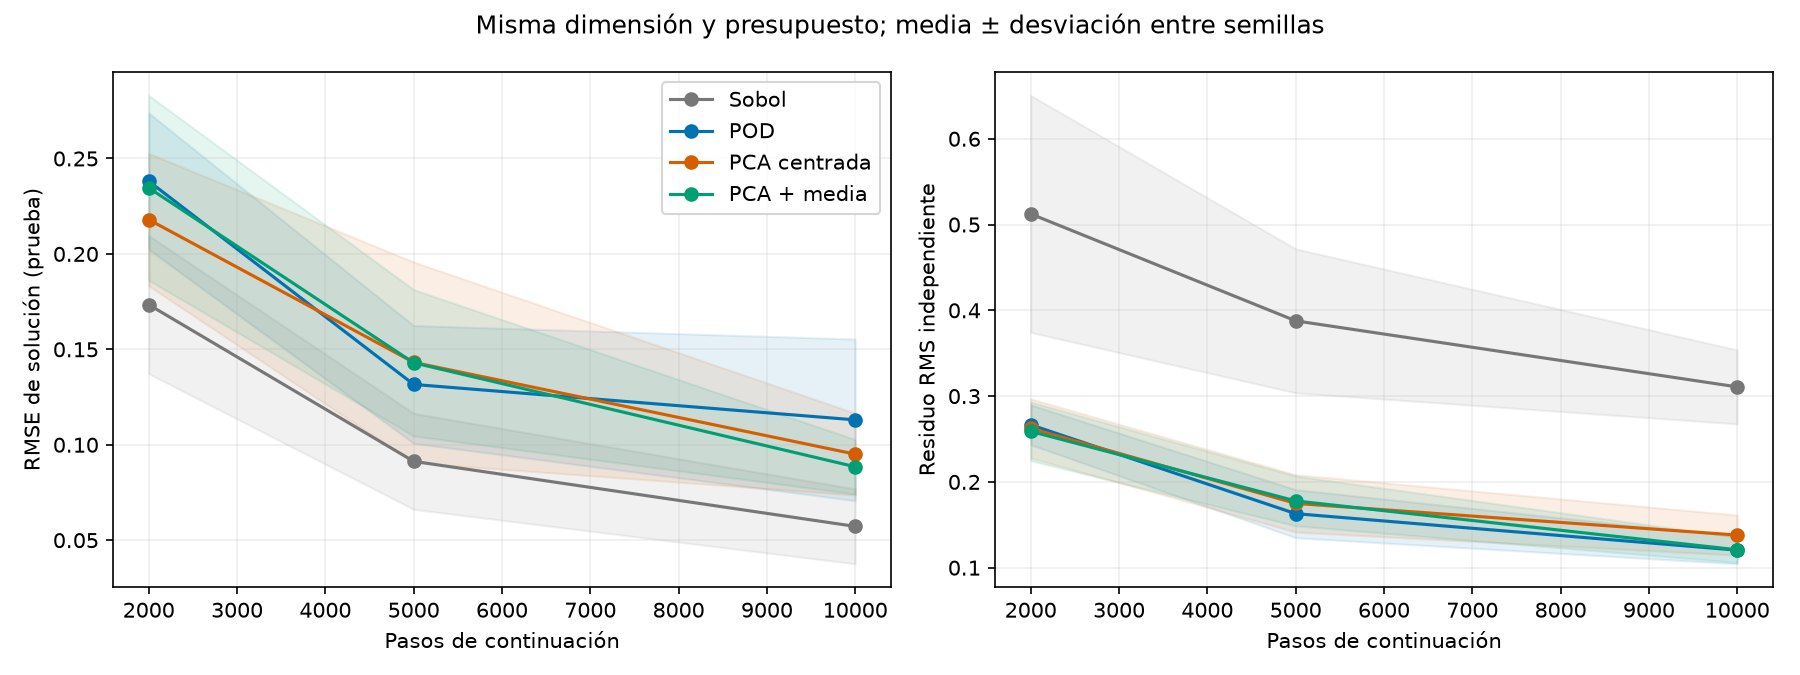

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/basis_ablation/fixed_dimension4_10_seeds_10k_v1/budget_comparison.png'), format='png', embed=True))


**paired_differences**

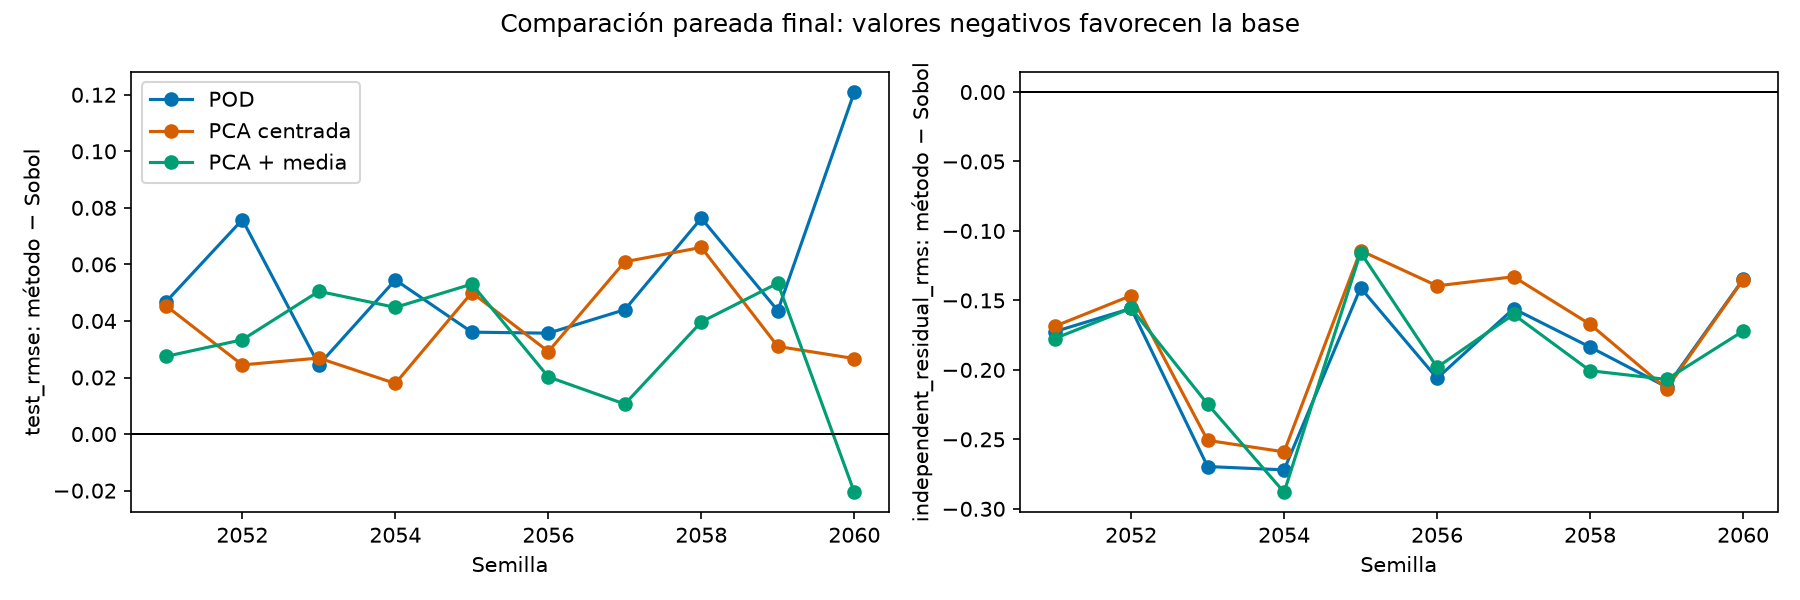

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/basis_ablation/fixed_dimension4_10_seeds_10k_v1/paired_differences.png'), format='png', embed=True))


## Qué está representando cada base

Se mide la fracción de norma cuadrada de la historia centrada y de su media recuperada al proyectarlas en la base. PCA maximiza la primera a dimensión fija; PCA + media garantiza conservar la segunda. Las curvas posteriores usan historias diferentes porque las redes ya evolucionaron de manera distinta. Para una comparación puramente geométrica, las siguientes selecciones y modos iniciales sí usan la misma matriz. Los ángulos entre esos subespacios están en initial_subspace_angles.json.

**basis_representation**

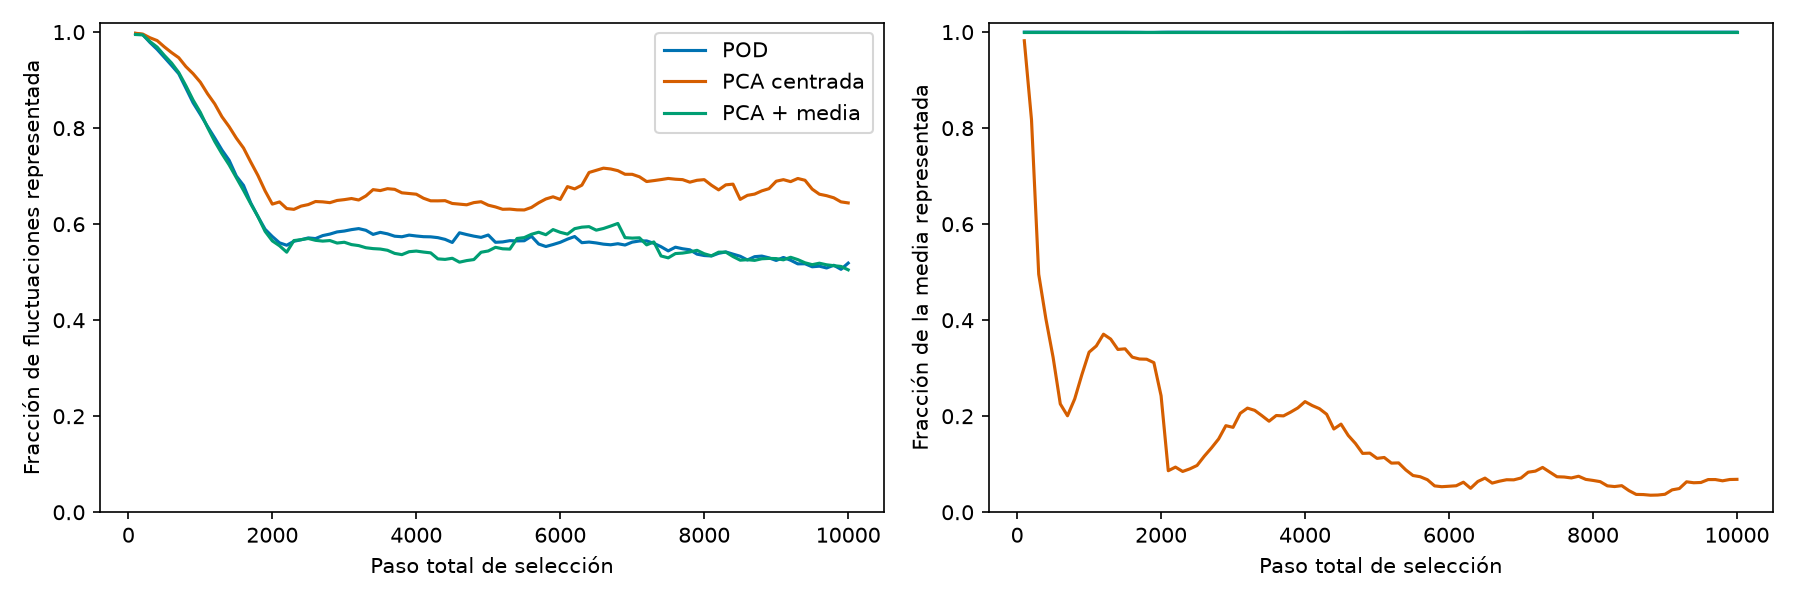

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/basis_ablation/fixed_dimension4_10_seeds_10k_v1/basis_representation.png'), format='png', embed=True))


**initial_selection**

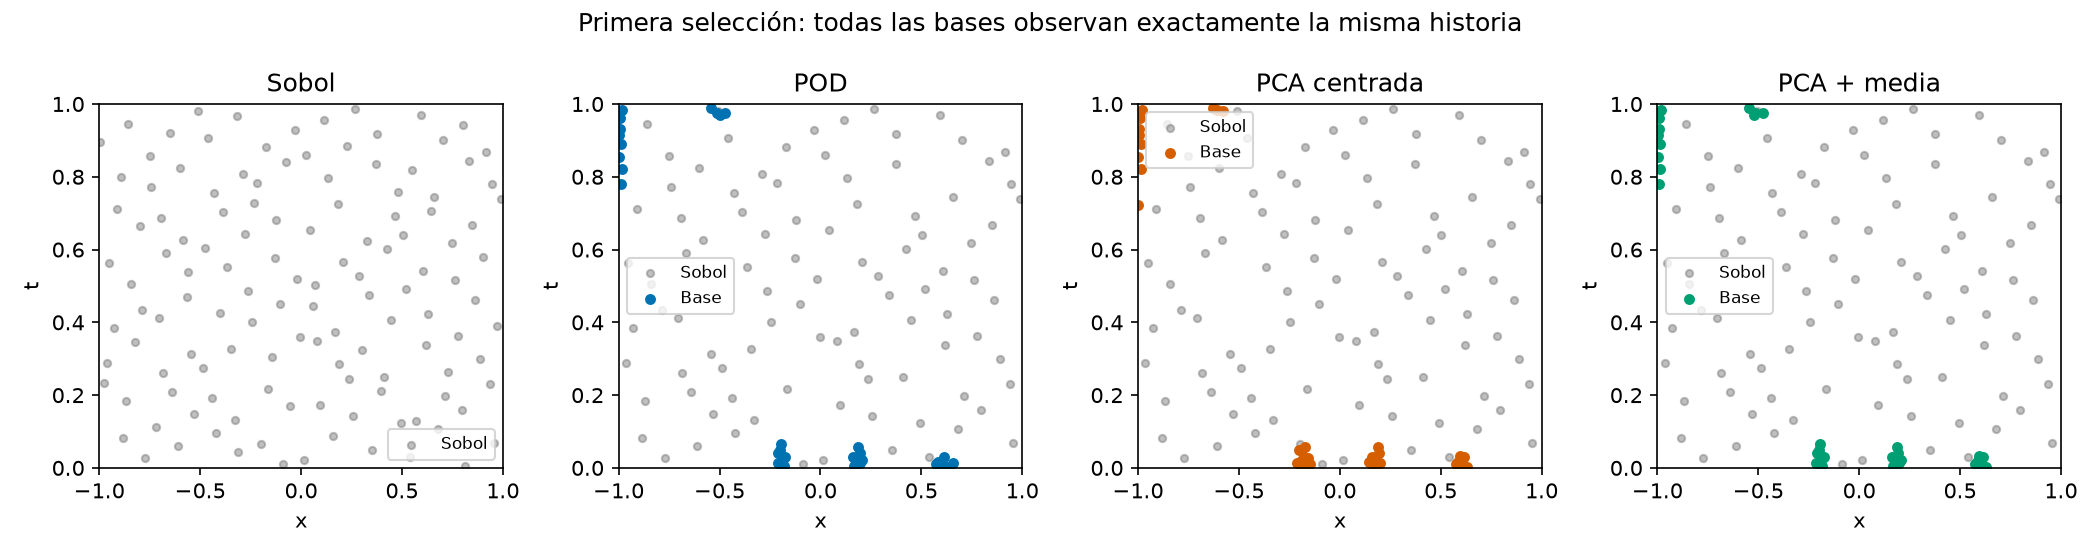

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/basis_ablation/fixed_dimension4_10_seeds_10k_v1/initial_selection.png'), format='png', embed=True))


**initial_modes**

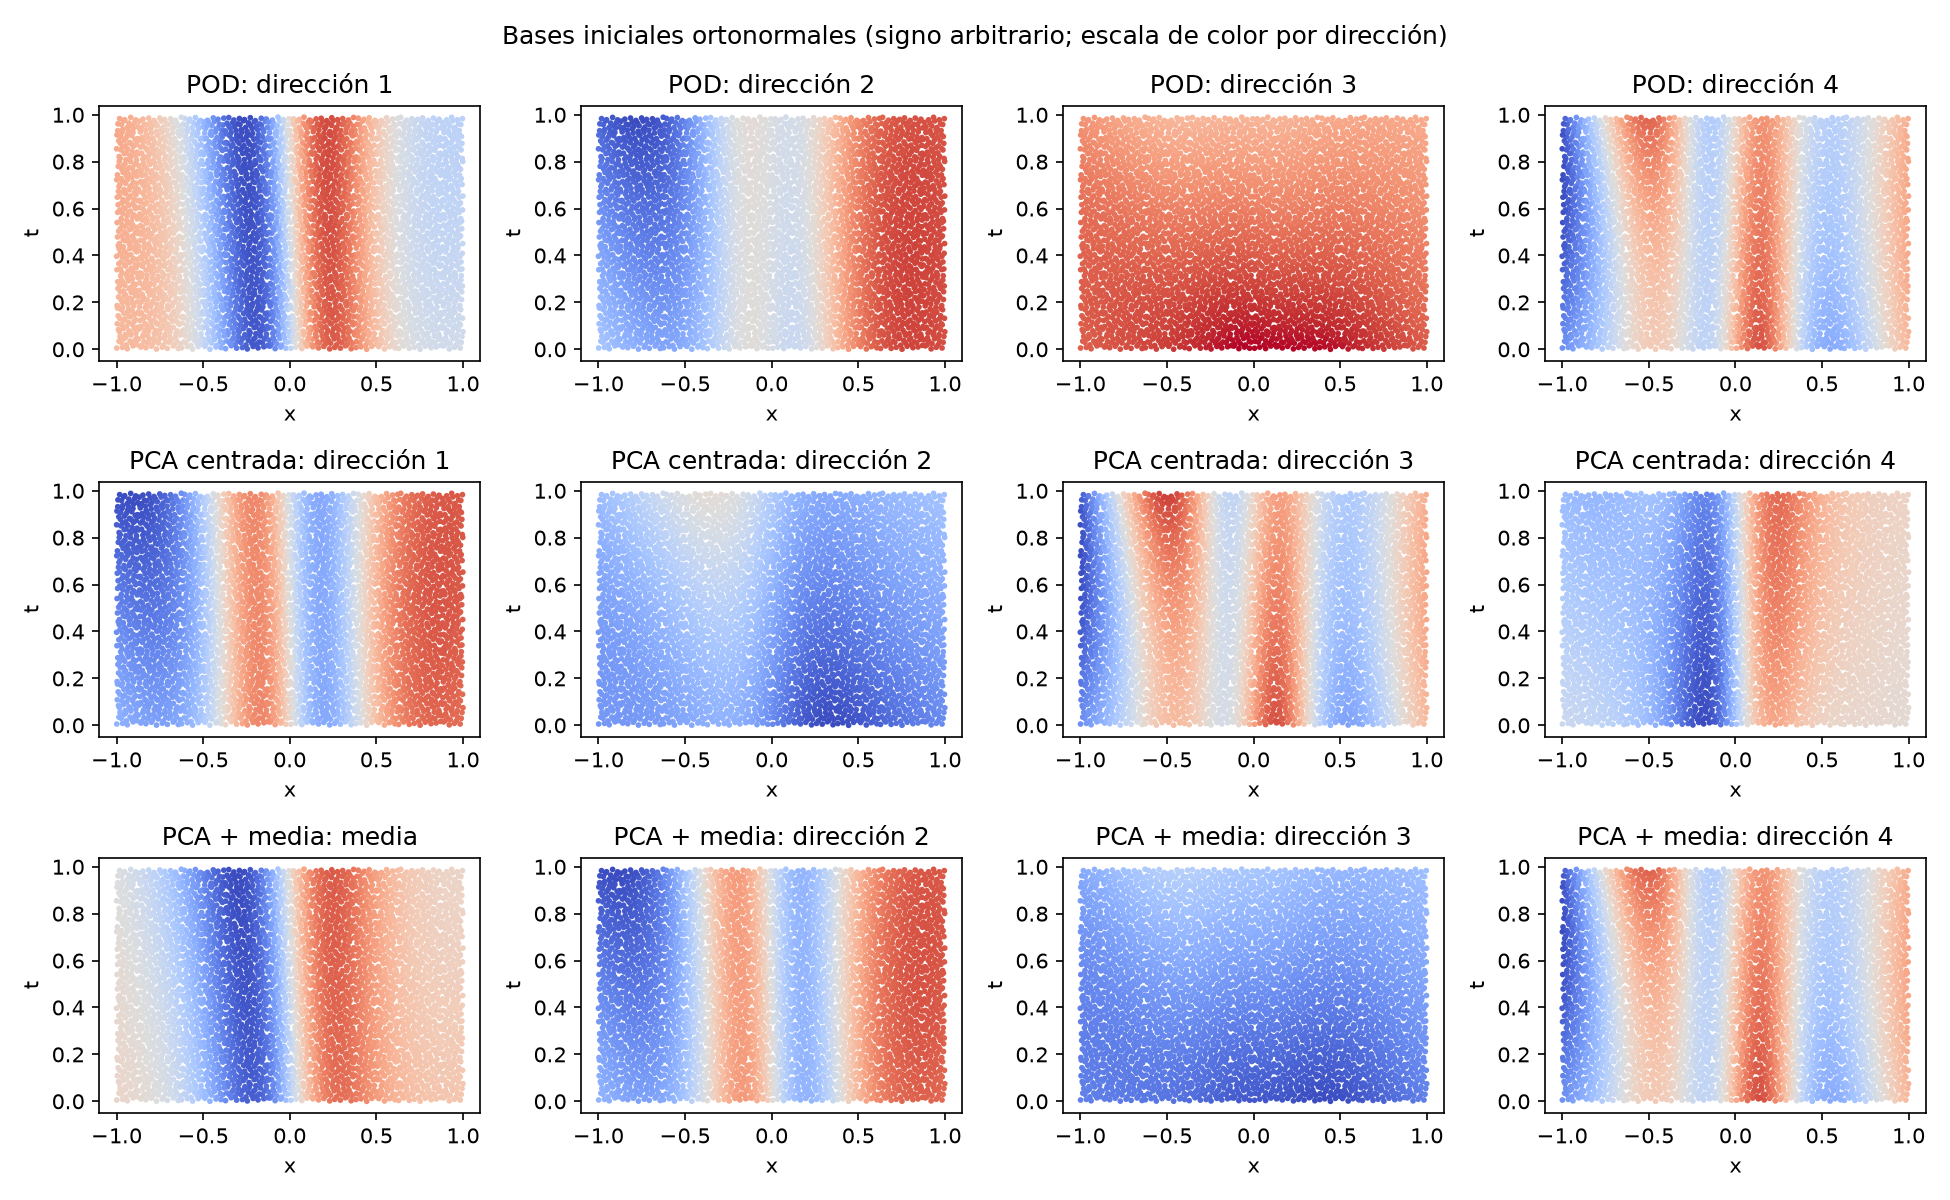

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/basis_ablation/fixed_dimension4_10_seeds_10k_v1/initial_modes.png'), format='png', embed=True))


**final_errors**

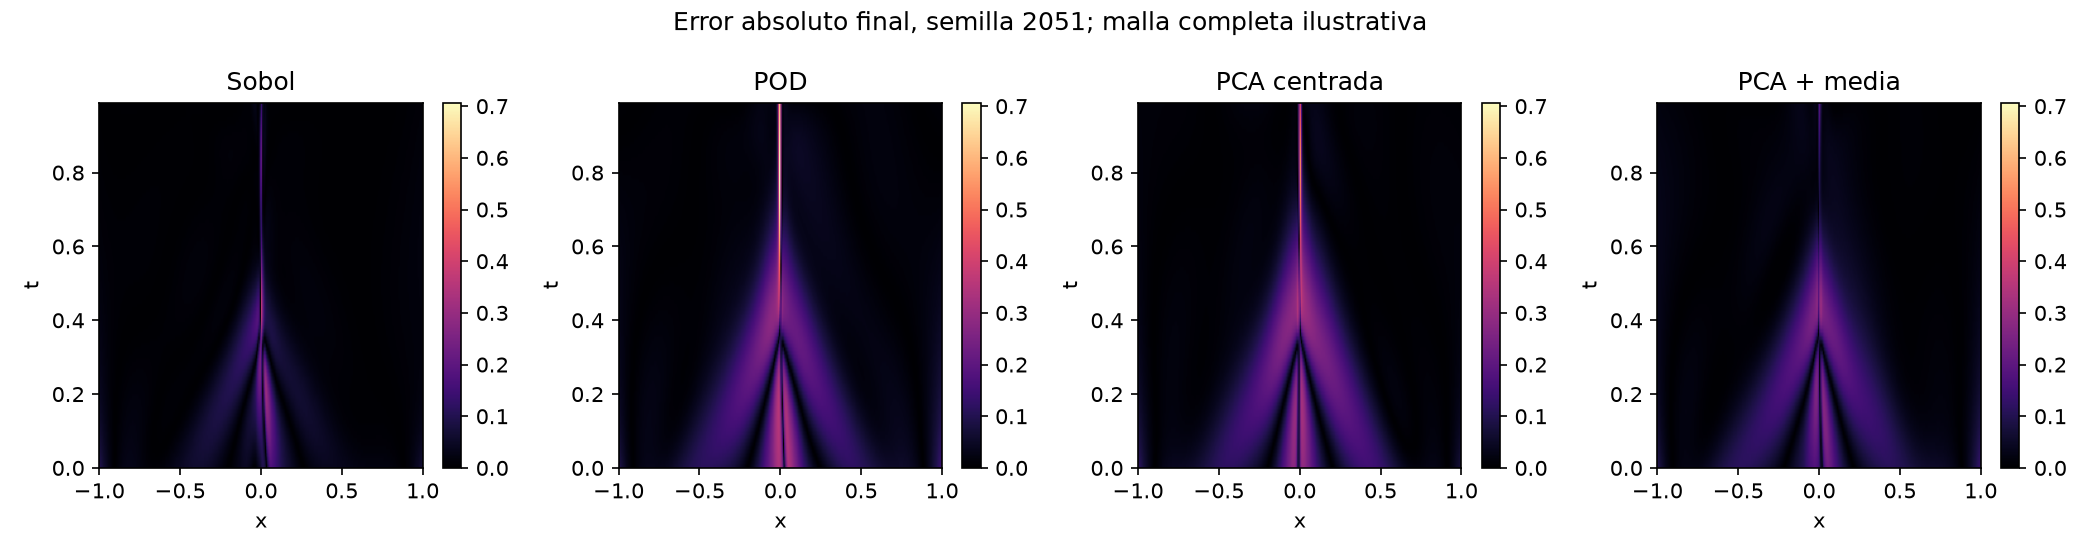

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/basis_ablation/fixed_dimension4_10_seeds_10k_v1/final_errors.png'), format='png', embed=True))


## Auditoría y reproducción

Se verificaron 4000 selecciones: dimensión igual, 32 puntos guiados, 128 activos únicos, complemento Sobol común y media conservada en PCA + media. Se verificó igualdad de métricas después del warmup. El control Sobol se contrastó además contra el experimento previo de 10000 pasos en 10 semillas.

```bash
python scripts/run_collocation_basis_ablation.py
python scripts/run_collocation_basis_ablation.py --report-only
```

Configuración: pca_collocation/configs/burgers_basis_ablation.json. Resultados: pca_collocation/results/burgers/basis_ablation/fixed_dimension4_10_seeds_10k_v1. Se guardan métricas, trazas, dimensión real, proyecciones, historial de puntos activos y campos ilustrativos. Las semillas completas se reutilizan; cambiar configuración requiere otro run_id. Las figuras están incrustadas como PNG.

El siguiente control será estudiar dimensión/rango manteniendo este mismo selector, sin cambiar simultáneamente historia, candidatos o poda.